# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

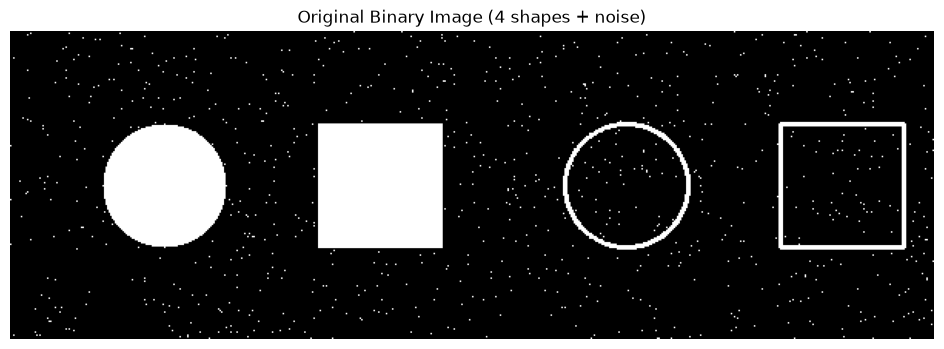

In [2]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [3]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



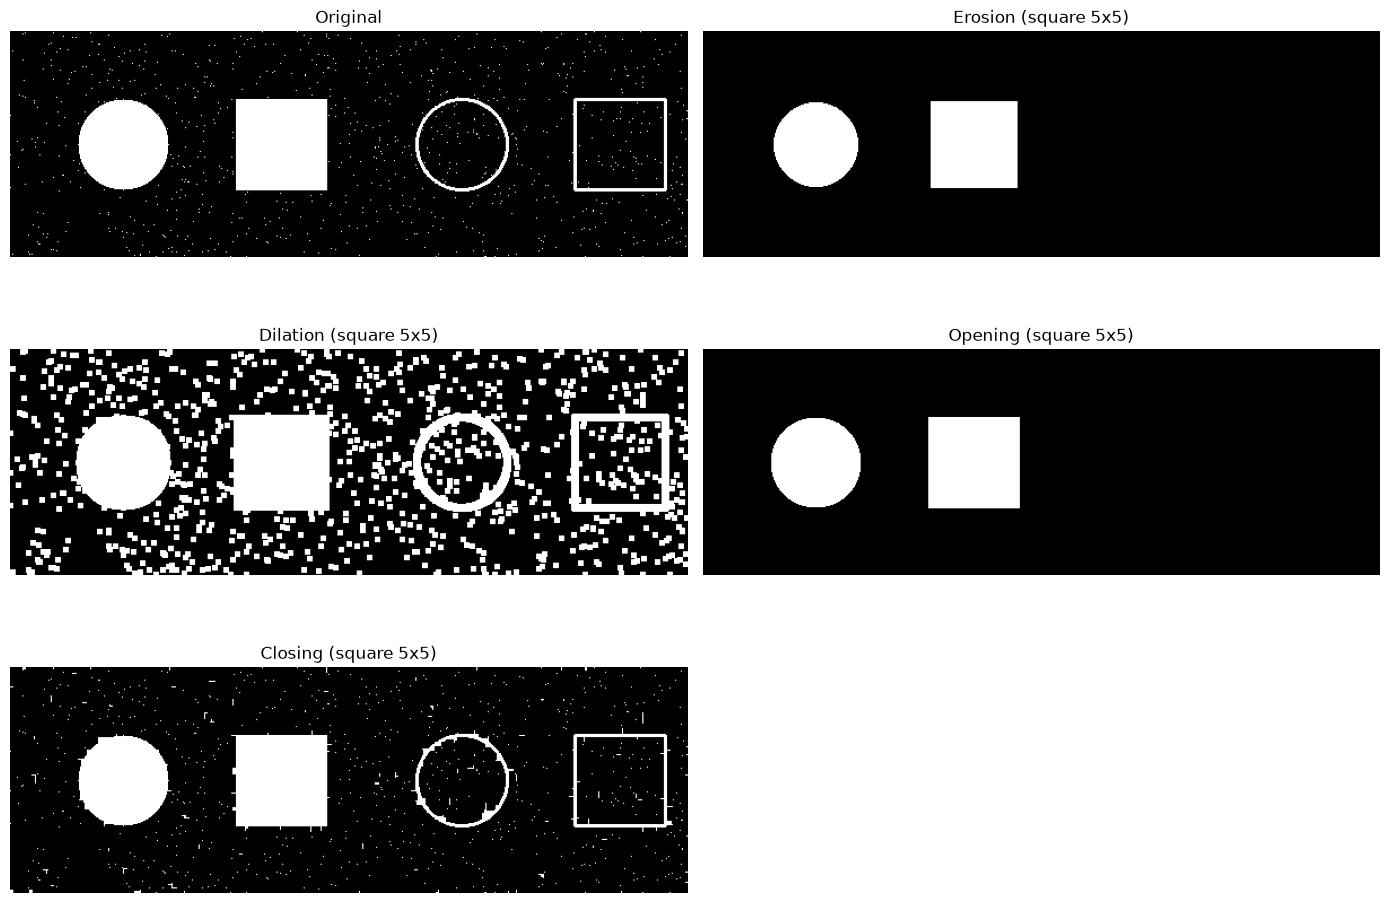

In [4]:
erosion_sq  = cv2.erode(image, kernel, iterations=1)
dilation_sq = cv2.dilate(image, kernel, iterations=1)
opening_sq  = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing_sq  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

results_sq = [
    ('Original', image),
    ('Erosion (square 5x5)', erosion_sq),
    ('Dilation (square 5x5)', dilation_sq),
    ('Opening (square 5x5)', opening_sq),
    ('Closing (square 5x5)', closing_sq),
]

plt.figure(figsize=(14, 10))
for i, (title, img) in enumerate(results_sq, 1):
    plt.subplot(3, 2, i)
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

In [5]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)

Circular kernel (11x11):
[[0 0 0 0 0 1 0 0 0 0 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]]


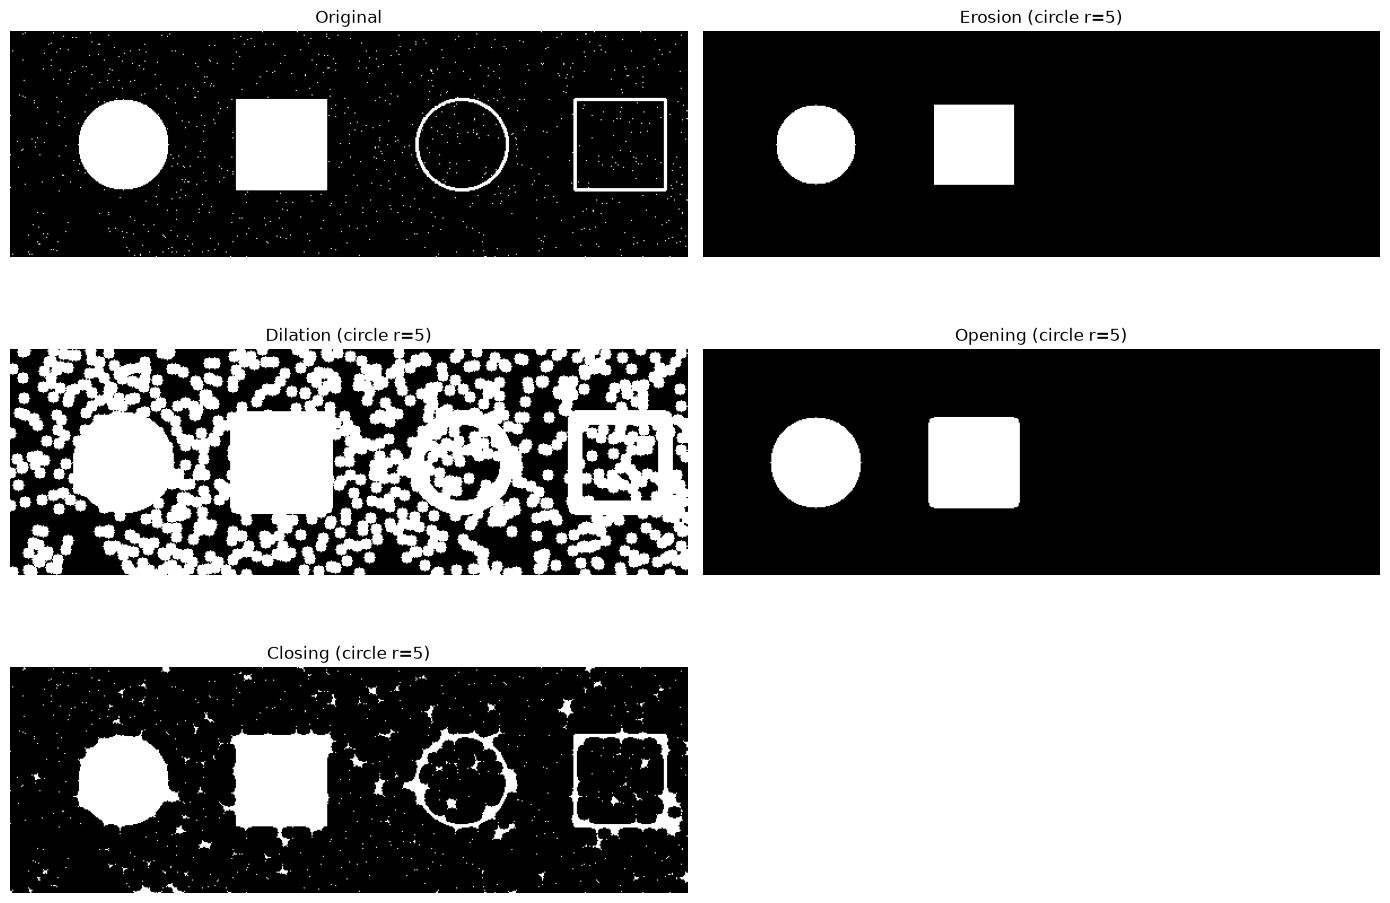

In [6]:
print("Circular kernel (11x11):")
print(circle_kernel)

erosion_c  = cv2.erode(image, circle_kernel, iterations=1)
dilation_c = cv2.dilate(image, circle_kernel, iterations=1)
opening_c  = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_c  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

results_c = [
    ('Original', image),
    ('Erosion (circle r=5)', erosion_c),
    ('Dilation (circle r=5)', dilation_c),
    ('Opening (circle r=5)', opening_c),
    ('Closing (circle r=5)', closing_c),
]

plt.figure(figsize=(14, 10))
for i, (title, img) in enumerate(results_c, 1):
    plt.subplot(3, 2, i)
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()

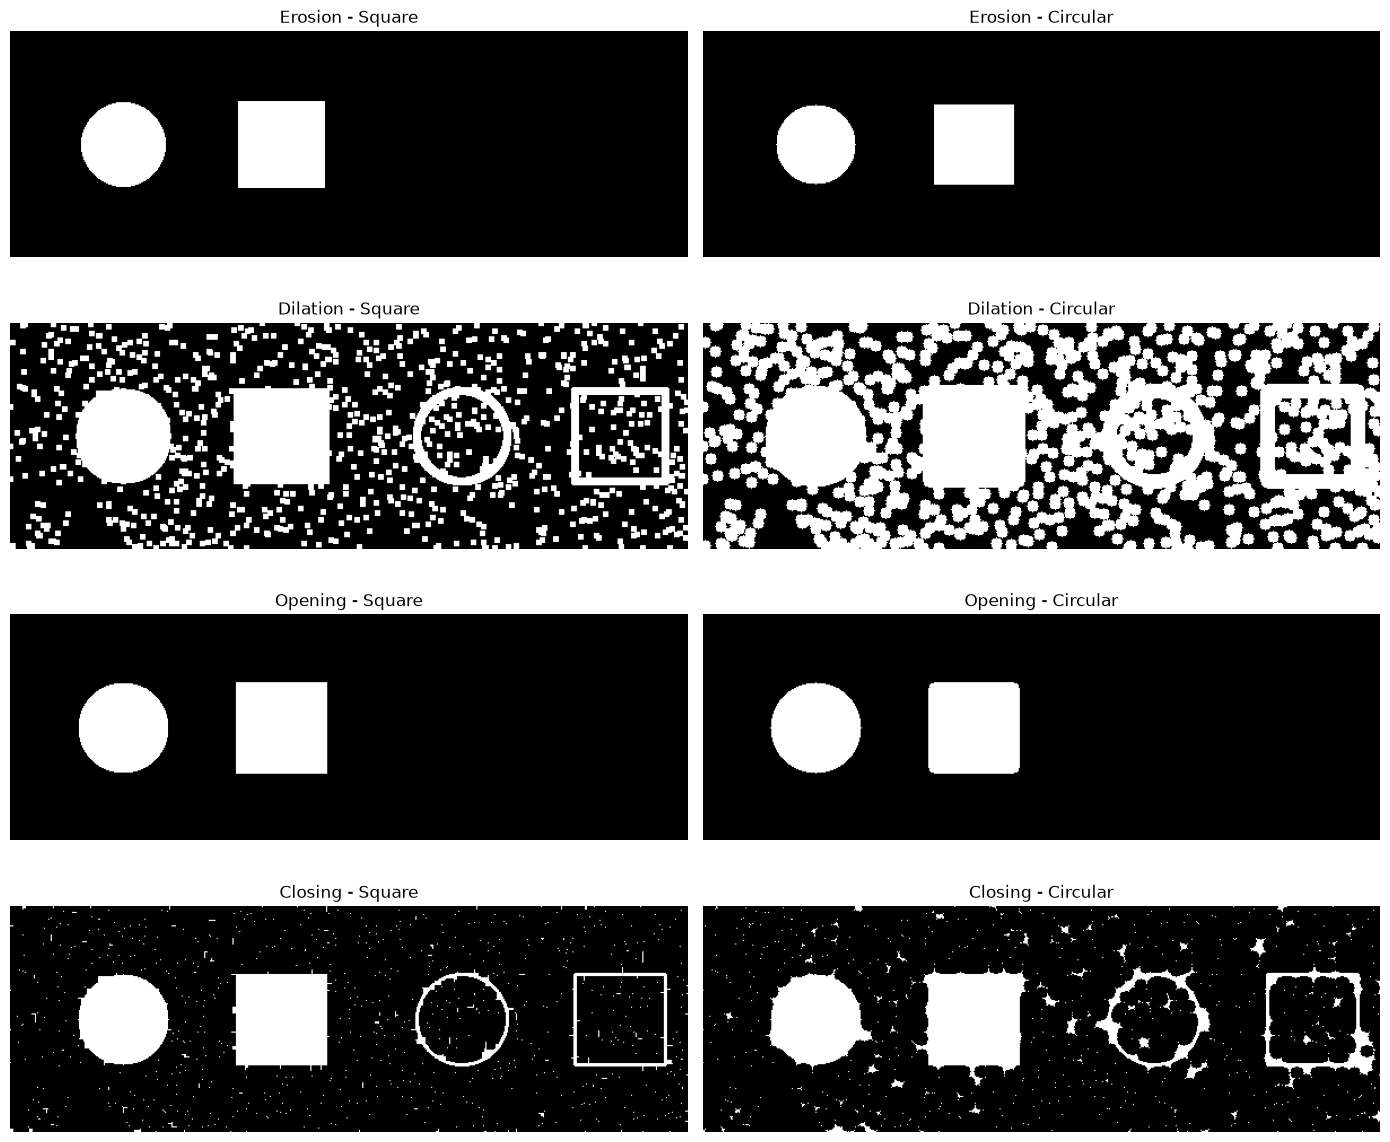

Operation     Square  Circular
Original       14165     14165
Erosion        10335      8903
Dilation       35685     67938
Opening        11583     11547
Closing        14707     17834


In [7]:
pairs = [
    ('Erosion',  erosion_sq,  erosion_c),
    ('Dilation', dilation_sq, dilation_c),
    ('Opening',  opening_sq,  opening_c),
    ('Closing',  closing_sq,  closing_c),
]

plt.figure(figsize=(14, 12))
k = 1
for name, sq, ci in pairs:
    plt.subplot(4, 2, k);     plt.imshow(sq, cmap='gray'); plt.title(f'{name} - Square');   plt.axis('off')
    plt.subplot(4, 2, k + 1); plt.imshow(ci, cmap='gray'); plt.title(f'{name} - Circular'); plt.axis('off')
    k += 2
plt.tight_layout()
plt.show()

# Number of white pixels (objects + noise) in each result
print(f"{'Operation':<10}{'Square':>10}{'Circular':>10}")
print(f"{'Original':<10}{int(np.count_nonzero(image)):>10}{int(np.count_nonzero(image)):>10}")
for name, sq, ci in pairs:
    print(f"{name:<10}{int(np.count_nonzero(sq)):>10}{int(np.count_nonzero(ci)):>10}")

## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



The shape of the structuring element directly determines the shape of the result. The 5×5 square kernel acts in blocks, so it keeps sharp corners: dilation turns each noise pixel into a small square, and opening keeps the rectangle’s corners sharp. The circular kernel (radius 5, so 11×11) acts uniformly in all directions, so it produces smooth, rounded results: dilation turns noise into round blobs that merge together, opening rounds the rectangle’s corners, and closing leaves star-shaped artifacts around the noise and distorts the hollow shapes more. Since the circular kernel is also larger, its effect is stronger. Erosion removed more pixels (10335 with the square vs. 8903 with the circle), dilation added far more (35685 vs. 67938), and closing added more (14707 vs. 17834). Both kernels removed the noise equally well with opening (11583 vs. 11547 white pixels), because single-pixel noise is smaller than either kernel. Both also erased the hollow shapes with erosion and opening, because their 2-pixel outlines are thinner than the kernels. Overall, the square kernel is better for preserving sharp corners and rectangular objects, while the circular kernel is better for smooth, direction-independent results on round objects, at the cost of rounding corners. Opening is the best operation for removing noise while preserving the size of real objects, whichever kernel is used.